# Experimental fast SfcTypeTIModel variants: a showcase

**EXPERIMENTAL.** This notebook demonstrates the prototype models in
`oggm/sandbox/sfc_type_fast.py`, written for the SfcTypeTIModel performance
study (see `REPORT.md` in this folder):

- `FastSfcTypeTIModel`: an **exact** re-implementation. It gives the same
  results as `SfcTypeTIModel` to floating point precision, and is faster
  thanks to block processing, a vectorised climate lookup, a precomputed
  calendar and an optional Numba kernel (with a numpy fallback).
- `FixedHeightSfcTypeTIModel`: an **approximate** variant. The snow and firn
  buckets live on fixed elevation levels. The whole bucket history is
  computed once as a table (time × elevation) and interpolated to the
  flowline heights.

We use Hintereisferner (HEF) from the OGGM test data with the HISTALP monthly
climate (see `README.md` for how to get the sample data offline).

In [1]:
import os, sys, time
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, os.getcwd())  # this folder, for the benchmark helpers
import common, plotstyle
from plotstyle import REF, SERIES, MUTED
plotstyle.setup()
%matplotlib inline

from oggm.utils import date_to_floatyear
from oggm.core.massbalance import SfcTypeTIModel, MonthlyTIModel
from oggm.sandbox import sfc_type_fast as sf
from oggm.sandbox.sfc_type_fast import (FastSfcTypeTIModel,
                                        FixedHeightSfcTypeTIModel, HAS_NUMBA)
print('Numba available:', HAS_NUMBA)

gdir = common.get_hef_gdir()
fl = common.main_model_flowline(gdir)
print(gdir.rgi_id, '- main flowline with', fl.nx, 'grid points, dx =',
      fl.dx_meter, 'm')

Numba available: True


RGI50-11.00897 - main flowline with 91 grid points, dx = 100.0 m


## 1. The exact model: same results, less time

`FastSfcTypeTIModel` takes the same arguments as `SfcTypeTIModel`, plus a few
switches: `kernel` (`'numba'`, `'numpy'` or `'auto'`), `batch_climate`,
`window_aging` and `debug_checks`. We run both for 1970–2002 on the main
flowline and compare all outputs.

In [2]:
def run(cls, store=True, **kw):
    # spinup (in the constructor) + annual MB 1970-2002, timed
    if store:
        kw.update(store_buckets='annual', store_snowline=True)
    sf.clear_caches()
    t0 = time.perf_counter()
    mb = cls(gdir, fl=fl, mb_model_class=MonthlyTIModel, ys=1970, **kw)
    out = np.array([mb.get_annual_mb(fl.surface_h, yr)
                    for yr in range(1970, 2003)])
    return mb, out, time.perf_counter() - t0

ref, mb_ref, t_ref = run(SfcTypeTIModel)
results = {'reference': (ref, mb_ref, t_ref)}
for kernel in ['numpy'] + (['numba'] if HAS_NUMBA else []):
    run(FastSfcTypeTIModel, kernel=kernel)  # warm-up (Numba compiles once)
    results[kernel] = run(FastSfcTypeTIModel, kernel=kernel)

for name, (mb, out, t) in results.items():
    d = np.max(np.abs(mb._climatic_mb[:mb._current_index] -
                      ref._climatic_mb[:ref._current_index]))
    print(f'{name:10s} {t * 1000:7.1f} ms  ({t_ref / t:4.1f}x)   '
          f'max |diff climatic_mb| = {d:.1e} kg m-2')

reference    116.5 ms  ( 1.0x)   max |diff climatic_mb| = 0.0e+00 kg m-2
numpy         92.1 ms  ( 1.3x)   max |diff climatic_mb| = 3.1e-12 kg m-2
numba         45.5 ms  ( 2.6x)   max |diff climatic_mb| = 3.1e-12 kg m-2


Storing the snowline (or the buckets every month) requires the state after
every step, so the fast model has to process the steps one by one, which
limits the gain. Without storing, the 12 months of each `get_annual_mb` call
are one block:

In [3]:
timings = {}
for name, cls, kw in [('reference', SfcTypeTIModel, {}),
                      ('numpy', FastSfcTypeTIModel, dict(kernel='numpy'))] + \
        ([('numba', FastSfcTypeTIModel, dict(kernel='numba'))]
         if HAS_NUMBA else []):
    timings[name] = min(run(cls, store=False, **kw)[2] for _ in range(3))
    print(f"{name:10s} {timings[name] * 1000:7.1f} ms  "
          f"({timings['reference'] / timings[name]:4.1f}x)")

reference     92.4 ms  ( 1.0x)
numpy         58.0 ms  ( 1.6x)


numba         16.4 ms  ( 5.6x)


The differences are of the order of 1e-12 kg m⁻² (only the order of the
summations differs). Stored buckets and the snowline are identical too:

In [4]:
fast = results['numba' if HAS_NUMBA else 'numpy'][0]
key = sorted(ref.mb_buckets_stored)[-1]
np.testing.assert_allclose(fast.mb_buckets_stored[key].values,
                           ref.mb_buckets_stored[key].values, atol=1e-9)
np.testing.assert_allclose(fast.snowline, ref.snowline)
print('buckets on', key, 'and snowline identical')

buckets on 2003.0 and snowline identical


### Calibration and dynamic run

The fast class is a drop-in replacement for `mb_model_class`. Here we compare
the `melt_f` calibration (brentq on 1970–2001, all three HEF flowlines) and a
dynamic run.

In [5]:
for name, cls in [('reference', SfcTypeTIModel),
                  ('fast', common.sfc_class(FastSfcTypeTIModel))]:
    t0 = time.perf_counter()
    df, _ = common.calibrate(gdir, cls)
    print(f"{name:10s} melt_f = {df['melt_f']:.8f}   "
          f"{time.perf_counter() - t0:.2f} s")

reference  melt_f = 9.80287213   1.34 s
fast       melt_f = 9.80287213   0.14 s


In [6]:
models = {}
for name, cls in [('reference', SfcTypeTIModel),
                  ('fast', common.sfc_class(FastSfcTypeTIModel)),
                  ('fixed dz=25 m', common.sfc_class(FixedHeightSfcTypeTIModel,
                                                     dz=25))]:
    sf.clear_caches()
    t0 = time.perf_counter()
    common.dynamic_run(gdir, cls, output_filesuffix='_nb_' + name[:5])
    import xarray as xr
    with xr.open_dataset(gdir.get_filepath('model_diagnostics',
                                           filesuffix='_nb_' + name[:5])) as ds:
        models[name] = ds.load()
    print(f'{name:14s} {time.perf_counter() - t0:.2f} s, final volume '
          f'{models[name].volume_m3[-1].item() * 1e-9:.4f} km3')

reference      1.33 s, final volume 0.7456 km3


fast           1.10 s, final volume 0.7456 km3


fixed dz=25 m  1.18 s, final volume 0.7455 km3


In the dynamic run most of the time is spent in the ice dynamics, so the
gain is smaller than in the calibration (see the report for the profile).

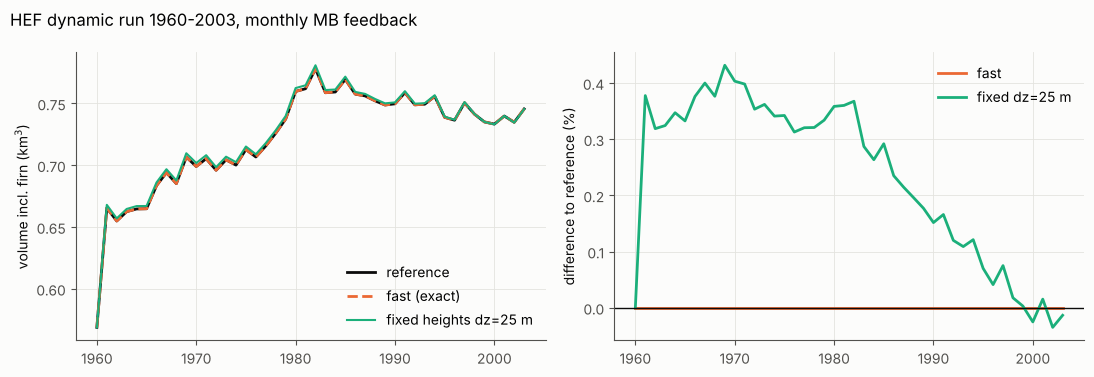

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
t = models['reference'].time
axs[0].plot(t, models['reference'].volume_m3 * 1e-9, color=REF,
            label='reference')
axs[0].plot(t, models['fast'].volume_m3 * 1e-9, '--', color=SERIES[1],
            label='fast (exact)')
axs[0].plot(t, models['fixed dz=25 m'].volume_m3 * 1e-9, color=SERIES[2],
            lw=1.5, label='fixed heights dz=25 m')
axs[0].set_ylabel('volume incl. firn (km$^3$)')
axs[0].legend()
for c, name in [(SERIES[1], 'fast'), (SERIES[2], 'fixed dz=25 m')]:
    axs[1].plot(t, 100 * (models[name].volume_m3 - models['reference'].volume_m3)
                / models['reference'].volume_m3, color=c, label=name)
axs[1].axhline(0, color=REF, lw=1)
axs[1].set_ylabel('difference to reference (%)')
axs[1].legend()
fig.suptitle('HEF dynamic run 1960-2003, monthly MB feedback', x=0.01,
             ha='left')
fig.tight_layout()

## 2. The fixed-height model

`FixedHeightSfcTypeTIModel(dz=...)` puts the buckets on elevation levels with
spacing `dz`, covering the whole glacier (from the lowest bed of the model
flowlines minus 100 m to the highest surface plus 300 m by default). The
first mass balance request computes the full table (spinup + all years up to
the end of the climate data) in one vectorised block. All later requests,
for any flowline of the same glacier and the same parameters, only
interpolate this table.

In [8]:
sf.clear_caches()
fix = FixedHeightSfcTypeTIModel(gdir, fl=fl, mb_model_class=MonthlyTIModel,
                                ys=1970, dz=25, store_snowline=True,
                                store_buckets='annual')
t0 = time.perf_counter()
mb_fix = np.array([fix.get_annual_mb(fl.surface_h, yr)
                   for yr in range(1970, 2003)])
print(f'{len(fix.z_levels)} levels from {fix.z_levels[0]:.0f} to '
      f'{fix.z_levels[-1]:.0f} m; {1e3 * (time.perf_counter() - t0):.1f} ms '
      'for the requests (the table was computed in the constructor, '
      'as ys is given)')
T = fix._table
print('table shape (steps x levels):', T.cmb.shape)

70 levels from 2225 to 3950 m; 31.7 ms for the requests (the table was computed in the constructor, as ys is given)
table shape (steps x levels): (468, 70)


### The table: annual climatic mass balance by elevation and year

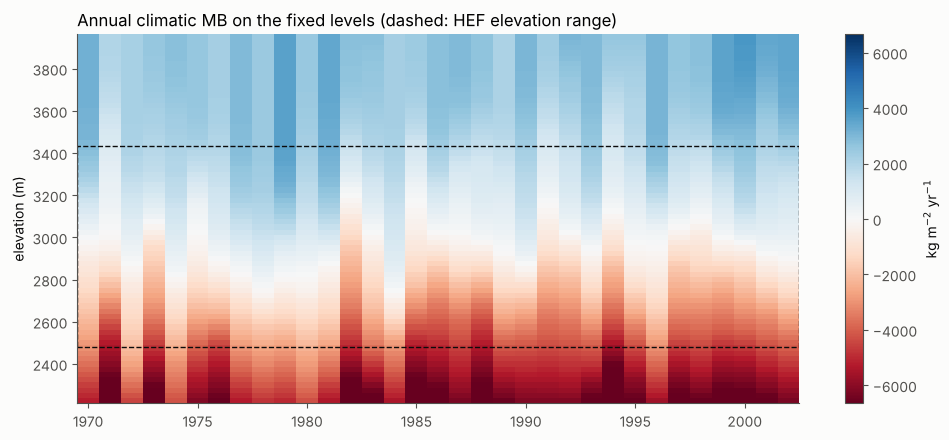

In [9]:
lm = fix._level_model
years = np.arange(1970, 2003)
tab = np.array([np.sum(T.cmb[lm._stored_timestep_indices(y, 'annual')],
                       axis=0) for y in years])  # (years, levels), kg m-2
fig, ax = plt.subplots(figsize=(10, 4.5))
lim = np.nanpercentile(np.abs(tab), 98)
im = ax.pcolormesh(years, fix.z_levels, tab.T, cmap='RdBu', vmin=-lim,
                   vmax=lim, shading='nearest')
glac = fl.thick > 0
ax.axhspan(fl.surface_h[glac].min(), fl.surface_h[glac].max(),
           color='none', ec=REF, lw=1, ls='--')
ax.set_ylabel('elevation (m)')
ax.set_title('Annual climatic MB on the fixed levels (dashed: HEF elevation '
             'range)', loc='left')
fig.colorbar(im, ax=ax, label='kg m$^{-2}$ yr$^{-1}$')
fig.tight_layout()

### Mass balance profiles: reference vs fixed heights

For fixed flowline heights (like in a calibration) the only error is the
linear interpolation between the levels.

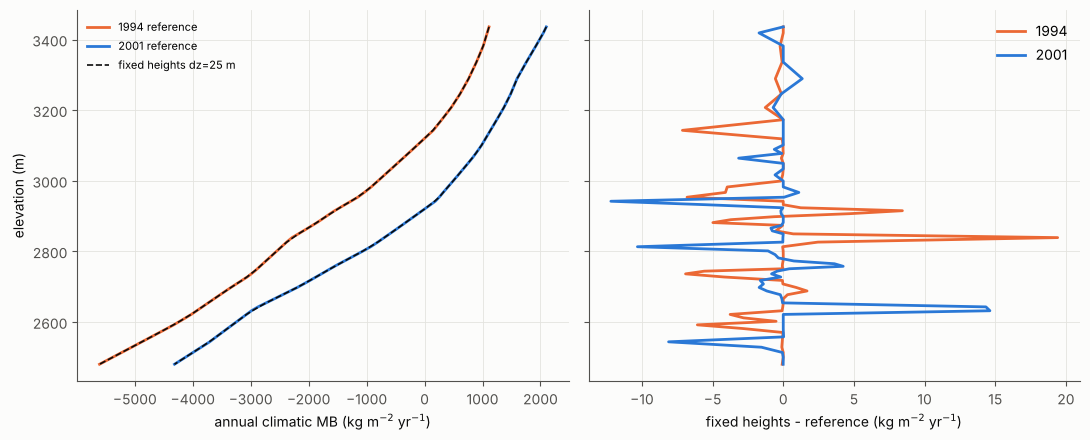

In [10]:
spy = 365 * 24 * 3600 * 900  # m ice s-1 -> kg m-2 yr-1 (approximately)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
h = fl.surface_h[glac]
for yr, c in [(1994, SERIES[1]), (2001, SERIES[0])]:
    i = yr - 1970
    axs[0].plot(mb_ref[i][glac] * spy, h, color=c, label=f'{yr} reference')
    axs[0].plot(mb_fix[i][glac] * spy, h, '--', color=REF, lw=1.2)
    axs[1].plot((mb_fix[i] - mb_ref[i])[glac] * spy, h, color=c,
                label=str(yr))
axs[0].plot([], [], '--', color=REF, lw=1.2, label='fixed heights dz=25 m')
axs[0].set_xlabel('annual climatic MB (kg m$^{-2}$ yr$^{-1}$)')
axs[0].set_ylabel('elevation (m)')
axs[0].legend(fontsize=8)
axs[1].set_xlabel('fixed heights - reference (kg m$^{-2}$ yr$^{-1}$)')
axs[1].legend()
fig.tight_layout()

### Accuracy and speed as a function of `dz`

Annual climatic MB on the glacier grid points, 1970–2002, fixed heights.

dz=   5 m: RMSE    0.2 kg m-2 yr-1,   49.7 ms
dz=  10 m: RMSE    0.6 kg m-2 yr-1,   33.7 ms
dz=  25 m: RMSE    2.5 kg m-2 yr-1,   26.4 ms
dz=  50 m: RMSE    6.8 kg m-2 yr-1,   29.4 ms
dz= 100 m: RMSE   21.8 kg m-2 yr-1,   23.0 ms
dz= 200 m: RMSE   64.2 kg m-2 yr-1,   22.5 ms


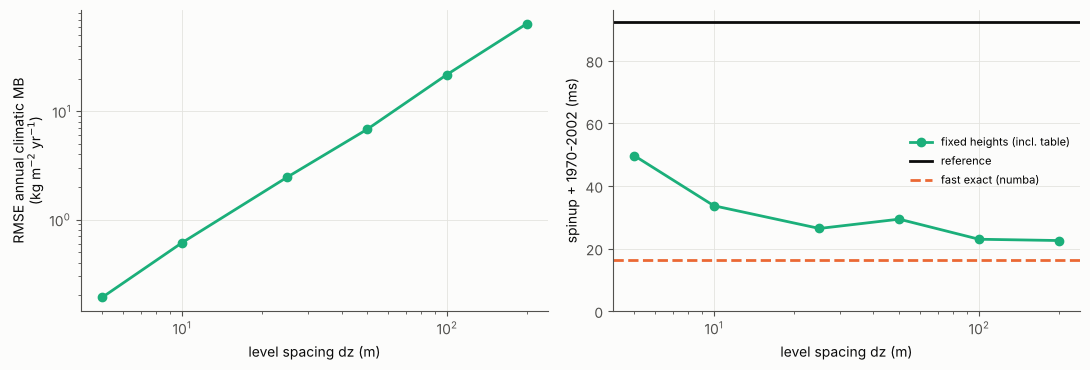

In [11]:
def fixed_run(dz):
    # timing includes the table computation (done in the constructor here)
    _, out, t = run(FixedHeightSfcTypeTIModel, store=False, dz=dz)
    return out, t

dzs = [5, 10, 25, 50, 100, 200]
rmse, tim = [], []
for dz in dzs:
    fixed_run(dz)
    out, t = min((fixed_run(dz) for _ in range(3)), key=lambda x: x[1])
    rmse.append(np.sqrt(np.mean(((out - mb_ref)[:, glac] * spy) ** 2)))
    tim.append(t)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].plot(dzs, rmse, 'o-', color=SERIES[2])
axs[0].set_xscale('log'); axs[0].set_yscale('log')
axs[0].set_xlabel('level spacing dz (m)')
axs[0].set_ylabel('RMSE annual climatic MB\n(kg m$^{-2}$ yr$^{-1}$)')
axs[1].plot(dzs, np.array(tim) * 1e3, 'o-', color=SERIES[2],
            label='fixed heights (incl. table)')
axs[1].axhline(timings['reference'] * 1e3, color=REF, label='reference')
if HAS_NUMBA:
    axs[1].axhline(timings['numba'] * 1e3, color=SERIES[1], ls='--',
                   label='fast exact (numba)')
axs[1].set_xscale('log')
axs[1].set_xlabel('level spacing dz (m)')
axs[1].set_ylabel('spinup + 1970-2002 (ms)')
axs[1].set_ylim(0, None)
axs[1].legend(fontsize=8)
fig.tight_layout()
for dz, r, t in zip(dzs, rmse, tim):
    print(f'dz={dz:4d} m: RMSE {r:6.1f} kg m-2 yr-1, {1e3 * t:6.1f} ms')

For a glacier of the size of HEF (69–91 grid points on the main flowline) the
exact Numba model is about as fast as, or faster than, the fixed-height model
for a single flowline, because the table covers more levels than the glacier
has grid points and the whole climate period up to the last year. The
fixed-height model pays off for long flowlines, many flowlines, and repeated
calls with the same parameters (the table is cached and shared).

### Snowline and snow/firn column

The snowline is derived from a signed snow signal on the levels (snow mass
where snow is left, minus the melt potential where it is gone), interpolated
to the grid points, and then the same rule as in the reference is applied.

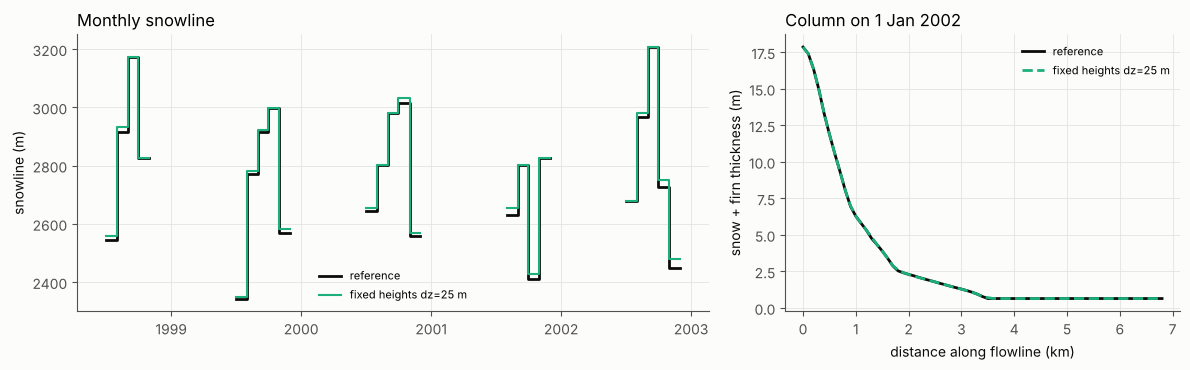

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8),
                        gridspec_kw={'width_ratios': [1.6, 1]})
sy = ref.snowline_year
sel = (sy >= 1998) & (sy < 2003)
axs[0].plot(sy[sel], ref.snowline[sel], color=REF, drawstyle='steps-post',
            label='reference')
axs[0].plot(fix.snowline_year[sel], fix.snowline[sel], color=SERIES[2],
            lw=1.5, drawstyle='steps-post', label='fixed heights dz=25 m')
axs[0].set_ylabel('snowline (m)')
axs[0].legend(fontsize=8)
axs[0].set_title('Monthly snowline', loc='left')

key = float(date_to_floatyear(2002, 1))
rho = ref._density_buckets_np[0, :-1]
x = fl.dx_meter * np.arange(fl.nx) / 1000
axs[1].plot(x[glac], (ref.mb_buckets_stored[key].values / rho).sum(axis=1)[glac],
            color=REF, label='reference')
axs[1].plot(x[glac], (fix.mb_buckets_stored[key].values / rho).sum(axis=1)[glac],
            '--', color=SERIES[2], label='fixed heights dz=25 m')
axs[1].set_xlabel('distance along flowline (km)')
axs[1].set_ylabel('snow + firn thickness (m)')
axs[1].set_title('Column on 1 Jan 2002', loc='left')
axs[1].legend(fontsize=8)
fig.tight_layout()

### Melt split by surface type

The table also stores the snow / firn / ice melt, so `get_annual_melt` works
as for the reference.

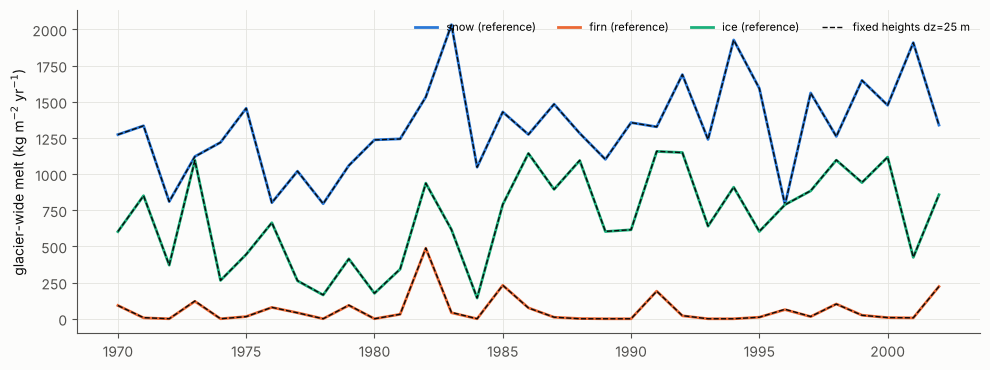

In [13]:
w = fl.widths_m[glac]
def melt(mb):
    return np.array([[np.average(m[glac], weights=w)
                      for m in mb.get_annual_melt(y)]
                     for y in range(1970, 2003)])
mr, mf_ = melt(ref), melt(fix)
fig, ax = plt.subplots(figsize=(10, 3.8))
for k, (lab, c) in enumerate(zip(['snow', 'firn', 'ice'], SERIES)):
    ax.plot(years, mr[:, k], color=c, label=f'{lab} (reference)')
    ax.plot(years, mf_[:, k], '--', color=REF, lw=1)
ax.plot([], [], '--', color=REF, lw=1, label='fixed heights dz=25 m')
ax.set_ylabel('glacier-wide melt (kg m$^{-2}$ yr$^{-1}$)')
ax.legend(ncol=4, fontsize=8)
fig.tight_layout()

## 3. Summary

- Use `FastSfcTypeTIModel` (with Numba installed) when the results must be
  identical to the reference: about 9× faster calibration on HEF and much better
  scaling for long flowlines. Without Numba the numpy path is about 1.3–1.8×
  faster.
- Use `FixedHeightSfcTypeTIModel` when an approximation is acceptable: with
  `dz=25 m` the annual MB error is a few kg m⁻² yr⁻¹, and once the table
  exists every mass balance request is a cheap interpolation.
- Both are prototypes. See `REPORT.md` for the full study and the open
  questions (saving/loading, `spinup_buckets`, daily climate).